# Inferences for Two Population Standard Deviations
---

## Experiment: the F-distribution from independent normal samples.

Empirical P(F > 2): 0.07565
Theoretical P(F > 2): 0.07773559157183135


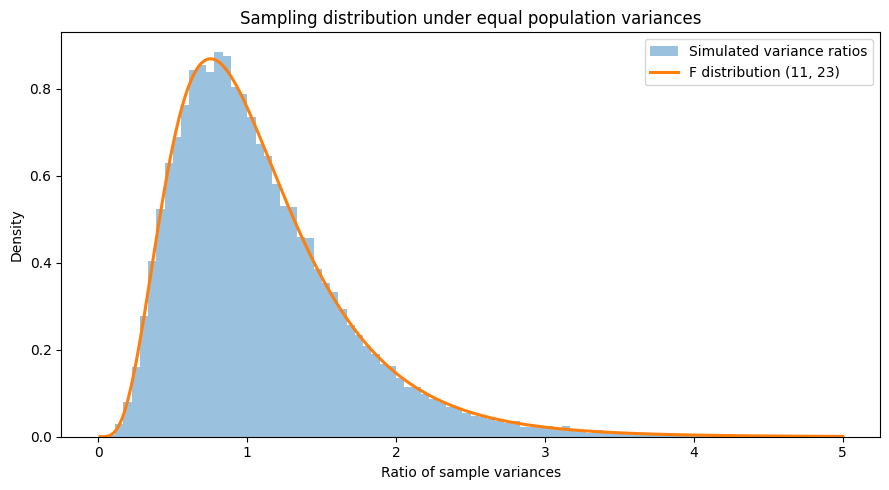

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import f

rng = np.random.default_rng(2026)
n1, n2 = 12, 24
nu1, nu2 = n1 - 1, n2 - 1
repetitions = 40_000

# The populations have equal variances but different means.
a = rng.normal(10, 3, size=(repetitions, n1))
b = rng.normal(25, 3, size=(repetitions, n2))

variance_ratios = a.var(axis=1, ddof=1) / b.var(axis=1, ddof=1)

print("Empirical P(F > 2):", np.mean(variance_ratios > 2))
print("Theoretical P(F > 2):", f.sf(2, nu1, nu2))

x = np.linspace(0.01, 5, 500)
fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(variance_ratios, bins=90, range=(0, 5), density=True,
        alpha=0.45, label="Simulated variance ratios")
ax.plot(x, f.pdf(x, nu1, nu2), linewidth=2.2,
        label=f"F distribution ({nu1}, {nu2})")
ax.set_xlabel("Ratio of sample variances")
ax.set_ylabel("Density")
ax.set_title("Sampling distribution under equal population variances")
ax.legend()
fig.tight_layout()
fig.savefig("../../images/two_sd_f_distribution.png", dpi=180, bbox_inches="tight")
plt.show()

# Experiment: swap n1 and n2. How does the distribution change?

## Experiment: F-tests from summary statistics.

In [2]:
from scipy.stats import f

n1, n2 = 14, 19
s1, s2 = 8.5, 4.2
nu1, nu2 = n1 - 1, n2 - 1

f_obs = s1**2 / s2**2
left_tail = f.cdf(f_obs, nu1, nu2)
right_tail = f.sf(f_obs, nu1, nu2)
two_sided_p = min(1.0, 2 * min(left_tail, right_tail))

alpha = 0.05
lower_critical = f.ppf(alpha / 2, nu1, nu2)
upper_critical = f.isf(alpha / 2, nu1, nu2)

print(f"F statistic: {f_obs:.5f}")
print(f"Left-sided p-value: {left_tail:.5f}")
print(f"Right-sided p-value: {right_tail:.5f}")
print(f"Two-sided p-value: {two_sided_p:.5f}")
print(f"Rejection limits: {lower_critical:.4f}, {upper_critical:.4f}")
print("Reject H0:", two_sided_p < alpha)

# Experiment: reverse the groups and exchange the degrees
# of freedom. Does the two-sided decision change?

F statistic: 4.09580
Left-sided p-value: 0.99671
Right-sided p-value: 0.00329
Two-sided p-value: 0.00658
Rejection limits: 0.3352, 2.7302
Reject H0: True


## Experiment: confidence intervals and reciprocal consistency.

In [3]:
import numpy as np
from scipy.stats import f

n1, n2 = 14, 19
s1, s2 = 8.5, 4.2
alpha = 0.05
nu1, nu2 = n1 - 1, n2 - 1
ratio = s1**2 / s2**2

variance_ci = (
    ratio / f.isf(alpha / 2, nu1, nu2),
    ratio / f.ppf(alpha / 2, nu1, nu2)
)
sd_ci = tuple(np.sqrt(variance_ci))

print("Variance ratio:", round(ratio, 4))
print("95% CI for variance ratio:", variance_ci)
print("95% CI for SD ratio:", sd_ci)

# Swapping groups reverses the ratio and its interval.
reverse_ratio = 1 / ratio
reverse_ci = (
    reverse_ratio / f.isf(alpha / 2, nu2, nu1),
    reverse_ratio / f.ppf(alpha / 2, nu2, nu1)
)

assert np.allclose(reverse_ci, (1 / variance_ci[1],
                                1 / variance_ci[0]))
print("CI after swapping groups:", reverse_ci)

# Experiment: increase both sample sizes while holding
# the sample SDs fixed. How does interval width change?

Variance ratio: 4.0958
95% CI for variance ratio: (1.500194324354633, 12.21876364887016)
95% CI for SD ratio: (1.2248242014079542, 3.4955348158572472)
CI after swapping groups: (0.08184134080476035, 0.6665803114741078)


## Experiment: type I error under normal and skewed sampling.

Normal: F-test=0.051, Brown-Forsythe=0.036
Lognormal: F-test=0.503, Brown-Forsythe=0.045


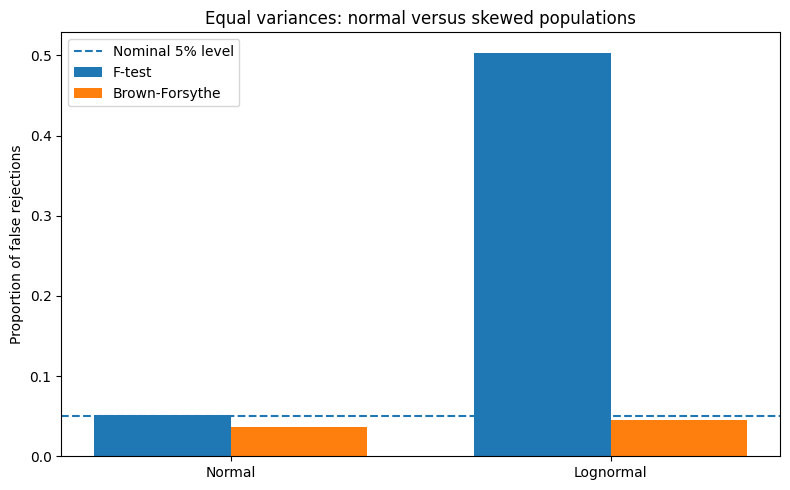

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import f, levene

rng = np.random.default_rng(2026)
repetitions = 4_000
n1, n2 = 20, 30
nu1, nu2 = n1 - 1, n2 - 1
alpha = 0.05

rejection_rates = {}

for name in ["Normal", "Lognormal"]:
    if name == "Normal":
        a = rng.normal(size=(repetitions, n1))
        b = rng.normal(size=(repetitions, n2))
    else:
        # Same lognormal distribution in both groups:
        # population variances are therefore equal.
        a = rng.lognormal(size=(repetitions, n1))
        b = rng.lognormal(size=(repetitions, n2))

    ratios = a.var(axis=1, ddof=1) / b.var(axis=1, ddof=1)
    p_f = np.minimum(
        1.0, 2 * np.minimum(f.cdf(ratios, nu1, nu2),
                            f.sf(ratios, nu1, nu2))
    )
    p_bf = levene(a, b, center="median", axis=1).pvalue
    rejection_rates[name] = (np.mean(p_f < alpha),
                             np.mean(p_bf < alpha))

for name, (rate_f, rate_bf) in rejection_rates.items():
    print(f"{name}: F-test={rate_f:.3f}, Brown-Forsythe={rate_bf:.3f}")

names = list(rejection_rates)
values = np.array(list(rejection_rates.values()))
x = np.arange(len(names))
fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(x - 0.18, values[:, 0], width=0.36, label="F-test")
ax.bar(x + 0.18, values[:, 1], width=0.36,
       label="Brown-Forsythe")
ax.axhline(alpha, linestyle="--", label="Nominal 5% level")
ax.set_xticks(x, names)
ax.set_ylabel("Proportion of false rejections")
ax.set_title("Equal variances: normal versus skewed populations")
ax.legend()
fig.tight_layout()
fig.savefig("../../images/two_sd_type1_nonnormal.png", dpi=180,
            bbox_inches="tight")
plt.show()

# Experiment: use heavy-tailed Student t observations
# instead of lognormal observations.

##  Experiment: confidence-interval coverage under nonnormality.

Target confidence level: 0.95
Normal coverage: 0.953
Lognormal coverage: 0.542


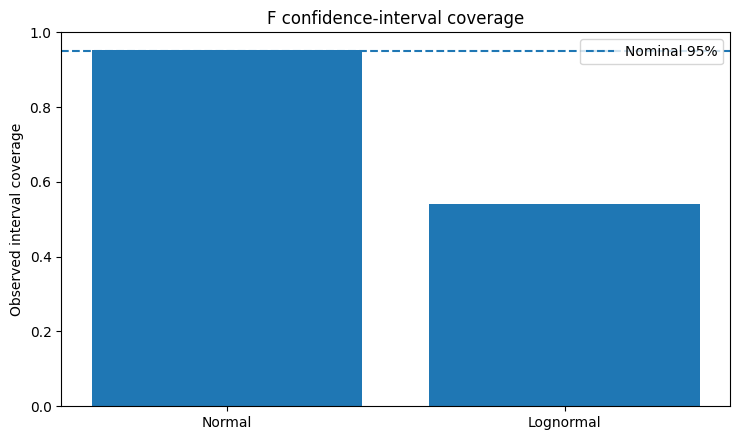

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import f

rng = np.random.default_rng(2027)
repetitions = 5_000
n1, n2 = 24, 36
nu1, nu2 = n1 - 1, n2 - 1
alpha = 0.05
true_ratio = 4.0  # Population SDs are 2 and 1.

coverage = {}

for name in ["Normal", "Lognormal"]:
    if name == "Normal":
        a = rng.normal(scale=2, size=(repetitions, n1))
        b = rng.normal(scale=1, size=(repetitions, n2))
    else:
        # Standardize lognormal samples to known population SD.
        shape = 0.9
        population_sd = np.sqrt(
            (np.exp(shape**2) - 1) * np.exp(shape**2)
        )
        a = 2 * rng.lognormal(sigma=shape,
                             size=(repetitions, n1)) / population_sd
        b = rng.lognormal(sigma=shape,
                          size=(repetitions, n2)) / population_sd

    ratios = a.var(axis=1, ddof=1) / b.var(axis=1, ddof=1)
    lower = ratios / f.isf(alpha / 2, nu1, nu2)
    upper = ratios / f.ppf(alpha / 2, nu1, nu2)
    coverage[name] = np.mean((lower <= true_ratio) &
                             (true_ratio <= upper))

print("Target confidence level: 0.95")
for name, rate in coverage.items():
    print(f"{name} coverage: {rate:.3f}")

fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.bar(list(coverage), list(coverage.values()))
ax.axhline(0.95, linestyle="--", label="Nominal 95%")
ax.set_ylim(0, 1)
ax.set_ylabel("Observed interval coverage")
ax.set_title("F confidence-interval coverage")
ax.legend()
fig.tight_layout()
fig.savefig("../../images/two_sd_ci_coverage.png", dpi=180,
            bbox_inches="tight")
plt.show()

# Experiment: increase sample size. Compare the coverage
# when the distribution is not normal.

## Experiment: comparing variance tests and diagnosing outliers.

Before adding an outlier:
SDs: 1.072, 0.962
F-test:        0.50486
Bartlett:      0.50485
Brown-Forsythe:0.88187
Fligner:       0.86963

After adding an outlier:
SDs: 1.072, 2.609
F-test:        0.00000
Bartlett:      0.00000
Brown-Forsythe:0.36522
Fligner:       0.73763


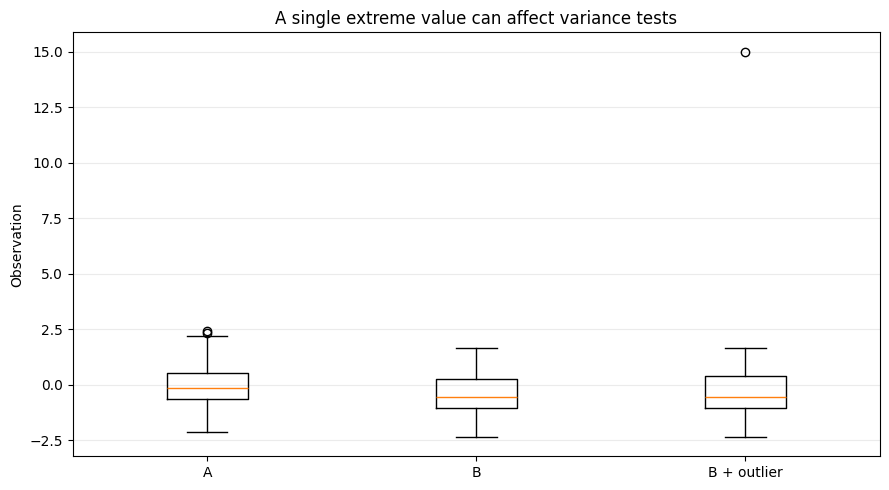

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import bartlett, f, fligner, levene

rng = np.random.default_rng(2027)
a = rng.normal(loc=0, scale=1, size=40)
b = rng.normal(loc=0, scale=1, size=40)
b_with_outlier = b.copy()
b_with_outlier[-1] = 15.0

def report(group1, group2):
    n1, n2 = len(group1), len(group2)
    observed = np.var(group1, ddof=1) / np.var(group2, ddof=1)
    p_f = min(1.0, 2 * min(f.cdf(observed, n1 - 1, n2 - 1),
                           f.sf(observed, n1 - 1, n2 - 1)))
    print(f"SDs: {np.std(group1, ddof=1):.3f}, "
          f"{np.std(group2, ddof=1):.3f}")
    print(f"F-test:        {p_f:.5f}")
    print(f"Bartlett:      {bartlett(group1, group2).pvalue:.5f}")
    print(f"Brown-Forsythe:{levene(group1, group2, center='median').pvalue:.5f}")
    print(f"Fligner:       {fligner(group1, group2).pvalue:.5f}")

print("Before adding an outlier:")
report(a, b)
print("\nAfter adding an outlier:")
report(a, b_with_outlier)

fig, ax = plt.subplots(figsize=(9, 5))
ax.boxplot([a, b, b_with_outlier], whis=1.5)
ax.set_xticks([1, 2, 3], ["A", "B", "B + outlier"])
ax.set_ylabel("Observation")
ax.set_title("A single extreme value can affect variance tests")
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
fig.savefig("../../images/two_sd_outlier_diagnostics.png", dpi=180,
            bbox_inches="tight")
plt.show()

# Experiment: replace 15 by 5, 10, and 30.
# Do all tests respond in the same way?

## Experiment: power and sample size for the two-sided F-test.

n=10, power at variance ratio 2: 0.158
n=25, power at variance ratio 2: 0.380
n=60, power at variance ratio 2: 0.752


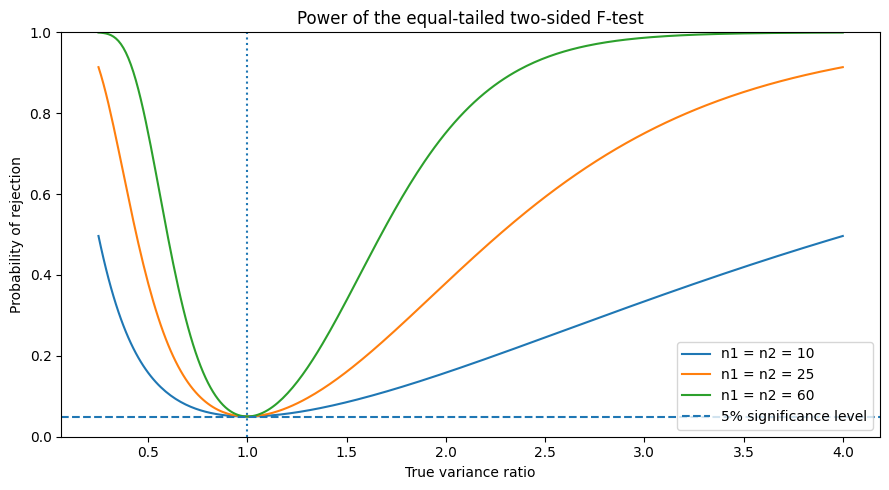

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import f

alpha = 0.05
ratios = np.linspace(0.25, 4, 300)
sample_sizes = [10, 25, 60]

fig, ax = plt.subplots(figsize=(9, 5))

for n in sample_sizes:
    nu1 = nu2 = n - 1
    lower_cutoff = f.ppf(alpha / 2, nu1, nu2)
    upper_cutoff = f.isf(alpha / 2, nu1, nu2)
    power = (
        f.cdf(lower_cutoff / ratios, nu1, nu2)
        + f.sf(upper_cutoff / ratios, nu1, nu2)
    )
    ax.plot(ratios, power, label=f"n1 = n2 = {n}")
    print(f"n={n}, power at variance ratio 2: "
          f"{f.cdf(lower_cutoff / 2, nu1, nu2) + f.sf(upper_cutoff / 2, nu1, nu2):.3f}")

ax.axhline(alpha, linestyle="--", label="5% significance level")
ax.axvline(1, linestyle=":")
ax.set_xlabel("True variance ratio")
ax.set_ylabel("Probability of rejection")
ax.set_title("Power of the equal-tailed two-sided F-test")
ax.set_ylim(0, 1)
ax.legend()
fig.tight_layout()
fig.savefig("../../images/two_sd_f_power.png", dpi=180, bbox_inches="tight")
plt.show()

# Experiment: determine a sample size giving 80% power
# for a true variance ratio of 2.

## Experiment: SOGA-Py student-height variability.

Female sample SD: 7.398
Male sample SD:   8.722
Variance ratio (female/male): 0.7193
Two-sided F-test p-value: 0.42560
Brown-Forsythe p-value: 0.37393
Fligner-Killeen p-value: 0.28744
95% F-based CI for variance ratio: (0.3169950879669459, 1.6324040428845388)
95% F-based CI for SD ratio: (0.5630231682328409, 1.2776556824452114)


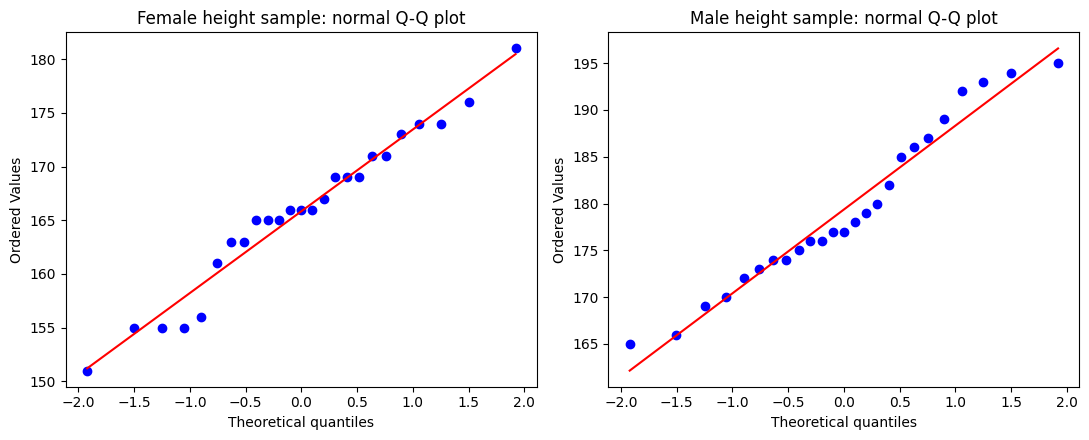

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import f, levene, fligner, probplot

url = "https://userpage.fu-berlin.de/soga/data/raw-data/students.csv"
students = pd.read_csv(url)

# Check group labels and choose nonmissing heights.
female_heights = students.loc[
    students["gender"] == "Female", "height"
].dropna().sample(n=25, random_state=8).to_numpy(dtype=float)

male_heights = students.loc[
    students["gender"] == "Male", "height"
].dropna().sample(n=25, random_state=8).to_numpy(dtype=float)

n1, n2 = len(female_heights), len(male_heights)
nu1, nu2 = n1 - 1, n2 - 1
s1 = np.std(female_heights, ddof=1)
s2 = np.std(male_heights, ddof=1)
ratio = (s1 / s2) ** 2

p_f = min(1.0, 2 * min(f.cdf(ratio, nu1, nu2),
                       f.sf(ratio, nu1, nu2)))
p_bf = levene(female_heights, male_heights,
              center="median").pvalue
p_fligner = fligner(female_heights, male_heights).pvalue

alpha = 0.05
variance_ci = (
    ratio / f.isf(alpha / 2, nu1, nu2),
    ratio / f.ppf(alpha / 2, nu1, nu2)
)

print(f"Female sample SD: {s1:.3f}")
print(f"Male sample SD:   {s2:.3f}")
print(f"Variance ratio (female/male): {ratio:.4f}")
print(f"Two-sided F-test p-value: {p_f:.5f}")
print(f"Brown-Forsythe p-value: {p_bf:.5f}")
print(f"Fligner-Killeen p-value: {p_fligner:.5f}")
print("95% F-based CI for variance ratio:", variance_ci)
print("95% F-based CI for SD ratio:", tuple(np.sqrt(variance_ci)))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
probplot(female_heights, dist="norm", plot=axes[0])
probplot(male_heights, dist="norm", plot=axes[1])
axes[0].set_title("Female height sample: normal Q-Q plot")
axes[1].set_title("Male height sample: normal Q-Q plot")
fig.tight_layout()
fig.savefig("../../images/two_sd_student_height_qq.png", dpi=180,
            bbox_inches="tight")
plt.show()

# Interpretation requires checking how the original
# data were collected, not just comparing p-values.